# 04 · Model development

**Goal:** Train models from the "dumbest" baseline up to tuned gradient boosting. Compare them fairly with **session-aware cross-validation** on the training sessions only. Pick 2–3 finalists, retrain them and save them.

**Inputs:**
- `data/processed/features.parquet` and `outputs/results/feature_list.json` (notebook 03)
- `outputs/results/split_profiles.json`: we use the **63 training sessions only**. The test set is not touched here.

**Outputs:**
- `outputs/results/cv_results.csv`: the comparison table
- `outputs/results/tuning_*.csv`: every tuning configuration tried
- `outputs/results/modelling_summary.json`, `model_metadata.json`
- `outputs/models/*.joblib`: the retrained finalists (git-ignored)
- Figures `model_01_cv_comparison.png`, `model_02_regularisation.png`

**Phase:** 4. The selection metric is **RMSE in °C (mean ± std over 5 folds)**. MAE and R² are also recorded.

## 1. Setup

In [1]:
import json
import random
import sys
import time
import warnings
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.model_selection import ParameterSampler
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src import config
from src.data import load_split
from src.modelling import CoolantPlusOffset, group_cv, regression_metrics, summarise_cv
from src.plotting import COLORS, save_figure, use_style

random.seed(config.SEED)
np.random.seed(config.SEED)
use_style()
config.MODELS_DIR.mkdir(parents=True, exist_ok=True)
N_JOBS = 16  # CPU cores on the laptop that ran this; lower it if your laptop struggles
print("scikit-learn", sklearn.__version__, "| lightgbm", lgb.__version__)

scikit-learn 1.9.1 | lightgbm 4.7.0


## 2. Load features and keep only the training sessions

In [2]:
feature_info = json.load(open(config.RESULTS_DIR / "feature_list.json"))
FEATURES = feature_info["features"]
RAW = feature_info["sets"]["raw"]
split = load_split()

feat = pd.read_parquet(config.PROJECT_DIR / "data" / "processed" / "features.parquet")
train = feat[feat[config.GROUP].isin(split["train_profiles"])]
del feat  # free memory; this notebook never needs the test rows
print("Training rows:", len(train), "| sessions:", train[config.GROUP].nunique(), "| features:", len(FEATURES))
assert not set(train[config.GROUP]) & set(split["test_profiles"])

Training rows: 1189792 | sessions: 63 | features: 45


## 3. The cross-validation protocol
- **GroupKFold(5), groups = `profile_id`:** the 63 training sessions are dealt into 5 folds. Each model is trained 5 times, each time on 4 folds and scored on the 5th, whose **sessions it has never seen**. So the score measures generalisation to *new sessions*, which is what we want. A normal random K-fold would put neighbouring 0.5 s rows on both sides and score far too well.
- **Subsampling (plan N6):** we keep **every 10th training row** (one row per 5 s). Neighbouring rows are near-copies, so this loses very little information but makes Random Forest about 10× faster. The EWMA features were computed *before* thinning (notebook 03), so they still carry the full-resolution history. Section 12 measures what the thinning costs.
- **Every model sees exactly the same rows and the same 5 folds**, so the comparison is fair.

In [3]:
K_CV = 10
cv_data = train.iloc[::K_CV]
X_all = cv_data[FEATURES]
X_raw = cv_data[RAW]
y = cv_data[config.TARGET].astype("float64")
groups = cv_data[config.GROUP]
print(f"CV rows: {len(cv_data)} (every {K_CV}th training row) from {groups.nunique()} sessions")

results = []
fold_tables = {}
oofs = {}
warnings.filterwarnings("ignore", message="Usage of np.ndarray subset")

def run(name, model, X, params=None):
    fold_table, oof = group_cv(model, X, y, groups)
    fold_tables[name] = fold_table
    oofs[name] = oof
    row = summarise_cv(name, fold_table, X.shape[1])
    row["params"] = json.dumps(params) if params else ""
    results.append(row)
    print(f"{name:32s} RMSE {row['rmse_mean']:.3f} ± {row['rmse_std']:.3f} °C | MAE {row['mae_mean']:.3f} | "
          f"R² {row['r2_mean']:.4f} | train RMSE {row['train_rmse_mean']:.3f} | {row['fit_seconds_per_fold']:.1f} s/fold")
    return row, oof

CV rows: 118980 (every 10th training row) from 63 sessions


## 4. Baselines (B0, B1)
- **B0, predict the training mean:** ignores every input. The "dumbest" possible model; anything useful must beat it.
- **B1, winding = coolant + a constant offset:** a physics-naive baseline. Is reading the coolant thermometer enough?

In [4]:
b0, _ = run("B0 mean", DummyRegressor(strategy="mean"), X_raw)
b1, _ = run("B1 coolant + offset", CoolantPlusOffset(), X_raw)

B0 mean                          RMSE 29.088 ± 1.258 °C | MAE 24.244 | R² -0.0309 | train RMSE 28.961 | 0.0 s/fold


B1 coolant + offset              RMSE 26.033 ± 1.636 °C | MAE 20.397 | R² 0.1586 | train RMSE 25.944 | 0.0 s/fold


## 5. Linear Regression (M1 raw inputs, M2 all 45 features)
Linear Regression fits the best straight-line (weighted-sum) formula `ŷ = w₁x₁ + … + b`. M1 uses only the 8 raw signals, M2 adds the physics and EWMA features. The difference between them shows how much our **feature engineering** adds. The scaler is inside a `Pipeline`, so it is fitted on the training folds only.

In [5]:
m1, _ = run("M1 Linear (8 raw)", Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]), X_raw)
m2, _ = run("M2 Linear (45 features)", Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]), X_all)

M1 Linear (8 raw)                RMSE 16.093 ± 1.600 °C | MAE 12.241 | R² 0.6808 | train RMSE 15.554 | 0.1 s/fold


M2 Linear (45 features)          RMSE 5.178 ± 0.565 °C | MAE 3.067 | R² 0.9663 | train RMSE 4.987 | 0.5 s/fold


## 6. Regularised linear models (M3: Ridge and Lasso)
**Regularisation** adds a penalty for large coefficients, so the model can't over-rely on any one feature. This helps when features are strongly correlated, as our EWMAs are.
- **Ridge (L2 penalty, α·Σw²):** shrinks all coefficients.
- **Lasso (L1 penalty, α·Σ|w|):** can push some coefficients to exactly 0, i.e. it drops features.

We tune α with the same group CV.

In [6]:
ridge_rows = []
for alpha in [0.01, 0.1, 1, 10, 100, 1000]:
    fold_table, _ = group_cv(Pipeline([("scale", StandardScaler()), ("model", Ridge(alpha=alpha))]), X_all, y, groups)
    ridge_rows.append({"alpha": alpha, "rmse_mean": fold_table["rmse"].mean(), "rmse_std": fold_table["rmse"].std(ddof=0)})
ridge_tuning = pd.DataFrame(ridge_rows)
ridge_tuning.to_csv(config.RESULTS_DIR / "tuning_ridge.csv", index=False)
best_ridge_alpha = float(ridge_tuning.loc[ridge_tuning["rmse_mean"].idxmin(), "alpha"])
print(ridge_tuning.round(4).to_string(index=False))
m3r, _ = run("M3 Ridge", Pipeline([("scale", StandardScaler()), ("model", Ridge(alpha=best_ridge_alpha))]), X_all,
             {"alpha": best_ridge_alpha})

  alpha  rmse_mean  rmse_std
   0.01     5.1778    0.5646
   0.10     5.1776    0.5648
   1.00     5.1760    0.5664
  10.00     5.1719    0.5764
 100.00     5.1983    0.5993
1000.00     5.3541    0.6612


M3 Ridge                         RMSE 5.172 ± 0.576 °C | MAE 3.052 | R² 0.9664 | train RMSE 4.992 | 0.3 s/fold


In [7]:
warnings.filterwarnings("ignore", category=ConvergenceWarning)
lasso_rows = []
for alpha in [0.01, 0.1, 1.0]:
    model = Pipeline([("scale", StandardScaler()), ("model", Lasso(alpha=alpha, max_iter=5000))])
    fold_table, _ = group_cv(model, X_all, y, groups)
    n_zero = int((model.fit(X_all, y).named_steps["model"].coef_ == 0).sum())
    lasso_rows.append({"alpha": alpha, "rmse_mean": fold_table["rmse"].mean(), "rmse_std": fold_table["rmse"].std(ddof=0),
                       "features_dropped": n_zero})
lasso_tuning = pd.DataFrame(lasso_rows)
lasso_tuning.to_csv(config.RESULTS_DIR / "tuning_lasso.csv", index=False)
best_lasso_alpha = float(lasso_tuning.loc[lasso_tuning["rmse_mean"].idxmin(), "alpha"])
print(lasso_tuning.round(4).to_string(index=False))
m3l, _ = run("M3 Lasso", Pipeline([("scale", StandardScaler()), ("model", Lasso(alpha=best_lasso_alpha, max_iter=5000))]), X_all,
             {"alpha": best_lasso_alpha})

lasso_full = Pipeline([("scale", StandardScaler()), ("model", Lasso(alpha=best_lasso_alpha, max_iter=5000))]).fit(X_all, y)
dropped = [f for f, w in zip(FEATURES, lasso_full.named_steps["model"].coef_) if w == 0]
print(f"Lasso (alpha={best_lasso_alpha}) dropped {len(dropped)} features:", dropped)

 alpha  rmse_mean  rmse_std  features_dropped
  0.01     5.2024    0.6153                11
  0.10     5.5208    0.7613                26
  1.00     6.5746    1.1756                34


M3 Lasso                         RMSE 5.202 ± 0.615 °C | MAE 3.019 | R² 0.9659 | train RMSE 5.046 | 23.2 s/fold


Lasso (alpha=0.01) dropped 11 features: ['ambient', 'u_d', 'p_el', 'i_s_ewma_120', 'i_s_ewma_600', 'i_s_ewma_5400', 'p_el_ewma_120', 'u_s_ewma_1800', 'motor_speed_ewma_120', 'torque_ewma_120', 'ambient_ewma_120']


## 7. Random Forest (M4)
A **decision tree** asks yes/no questions ("is i_s_ewma_600 > 150?") to split the data into groups with similar temperatures. A **Random Forest** grows many trees, each on a random sample of rows and features, and averages them (**bagging**). Averaging cancels out the individual trees' mistakes.

Random Forest is our slowest model, so we try **4 random configurations** (`ParameterSampler`, seed 42) with 100 trees each and `max_samples=0.5` (each tree sees half the rows).

In [8]:
rf_space = {"max_depth": [12, 20, None], "min_samples_leaf": [5, 20, 50], "max_features": [0.33, 0.5]}
rf_rows, rf_best = [], None
for cfg in ParameterSampler(rf_space, n_iter=4, random_state=config.SEED):
    model = RandomForestRegressor(n_estimators=100, max_samples=0.5, n_jobs=N_JOBS, random_state=config.SEED, **cfg)
    fold_table, _ = group_cv(model, X_all, y, groups)
    row = {**cfg, "rmse_mean": fold_table["rmse"].mean(), "rmse_std": fold_table["rmse"].std(ddof=0),
           "train_rmse": fold_table["train_rmse"].mean(), "fit_seconds": fold_table["fit_seconds"].mean()}
    rf_rows.append(row)
    print(row)
rf_tuning = pd.DataFrame(rf_rows)
rf_tuning.to_csv(config.RESULTS_DIR / "tuning_rf.csv", index=False)
best_rf = rf_tuning.loc[rf_tuning["rmse_mean"].idxmin()]
best_rf_params = {"max_depth": None if pd.isna(best_rf["max_depth"]) else int(best_rf["max_depth"]),
                  "min_samples_leaf": int(best_rf["min_samples_leaf"]), "max_features": float(best_rf["max_features"])}
m4, _ = run("M4 Random Forest", RandomForestRegressor(n_estimators=100, max_samples=0.5, n_jobs=N_JOBS,
                                                       random_state=config.SEED, **best_rf_params), X_all, best_rf_params)

{'min_samples_leaf': 5, 'max_features': 0.33, 'max_depth': 12, 'rmse_mean': np.float64(5.920908864577103), 'rmse_std': np.float64(1.2035449508591378), 'train_rmse': np.float64(1.7771599733095287), 'fit_seconds': np.float64(34.53307795524597)}


{'min_samples_leaf': 20, 'max_features': 0.33, 'max_depth': 12, 'rmse_mean': np.float64(5.822320779520321), 'rmse_std': np.float64(0.8443339920683016), 'train_rmse': np.float64(2.3268582010419037), 'fit_seconds': np.float64(14.37406907081604)}


{'min_samples_leaf': 50, 'max_features': 0.33, 'max_depth': 20, 'rmse_mean': np.float64(5.905083961386643), 'rmse_std': np.float64(0.6316583322998405), 'train_rmse': np.float64(3.0041526638192706), 'fit_seconds': np.float64(11.714885377883911)}


{'min_samples_leaf': 50, 'max_features': 0.5, 'max_depth': 12, 'rmse_mean': np.float64(5.859486998362889), 'rmse_std': np.float64(0.4464323209411034), 'train_rmse': np.float64(3.0057283297473445), 'fit_seconds': np.float64(15.065608549118043)}


M4 Random Forest                 RMSE 5.822 ± 0.844 °C | MAE 3.787 | R² 0.9579 | train RMSE 2.327 | 10.3 s/fold


## 8. Gradient boosting with LightGBM (M5)
**Gradient boosting** also uses many trees, but builds them **one after another**: each new tree tries to fix the errors the previous trees still make. LightGBM is a fast implementation. We try **8 random configurations**.

**Trap avoided:** LightGBM can stop early using a validation set. If it picked those rows at random, it would mix rows from the same session and give over-optimistic scores. We use **no early stopping**: a fixed number of trees, judged only by our session-wise folds.

In [9]:
lgbm_space = {"num_leaves": [15, 31, 63, 127], "learning_rate": [0.03, 0.05, 0.1], "n_estimators": [300, 600, 1000],
              "min_child_samples": [20, 100, 300], "colsample_bytree": [0.7, 1.0], "subsample": [0.8, 1.0]}
lgbm_rows = []
for cfg in ParameterSampler(lgbm_space, n_iter=8, random_state=config.SEED):
    model = lgb.LGBMRegressor(subsample_freq=1, n_jobs=N_JOBS, random_state=config.SEED, verbose=-1, **cfg)
    fold_table, _ = group_cv(model, X_all, y, groups)
    row = {**cfg, "rmse_mean": fold_table["rmse"].mean(), "rmse_std": fold_table["rmse"].std(ddof=0),
           "train_rmse": fold_table["train_rmse"].mean(), "fit_seconds": fold_table["fit_seconds"].mean()}
    lgbm_rows.append(row)
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items()})
lgbm_tuning = pd.DataFrame(lgbm_rows)
lgbm_tuning.to_csv(config.RESULTS_DIR / "tuning_lgbm.csv", index=False)
best_lgbm = lgbm_tuning.loc[lgbm_tuning["rmse_mean"].idxmin()]
best_lgbm_params = {k: (int(best_lgbm[k]) if k in ["num_leaves", "n_estimators", "min_child_samples"] else float(best_lgbm[k]))
                    for k in lgbm_space}
m5, oof_lgbm = run("M5 LightGBM", lgb.LGBMRegressor(subsample_freq=1, n_jobs=N_JOBS, random_state=config.SEED, verbose=-1,
                                                     **best_lgbm_params), X_all, best_lgbm_params)

{'subsample': 0.8, 'num_leaves': 15, 'n_estimators': 1000, 'min_child_samples': 300, 'learning_rate': 0.1, 'colsample_bytree': 1.0, 'rmse_mean': np.float64(5.061), 'rmse_std': np.float64(0.836), 'train_rmse': np.float64(1.144), 'fit_seconds': np.float64(5.656)}


{'subsample': 1.0, 'num_leaves': 31, 'n_estimators': 300, 'min_child_samples': 20, 'learning_rate': 0.05, 'colsample_bytree': 0.7, 'rmse_mean': np.float64(5.399), 'rmse_std': np.float64(1.02), 'train_rmse': np.float64(1.41), 'fit_seconds': np.float64(2.283)}


{'subsample': 0.8, 'num_leaves': 63, 'n_estimators': 600, 'min_child_samples': 100, 'learning_rate': 0.1, 'colsample_bytree': 0.7, 'rmse_mean': np.float64(5.165), 'rmse_std': np.float64(0.955), 'train_rmse': np.float64(0.622), 'fit_seconds': np.float64(5.607)}


{'subsample': 0.8, 'num_leaves': 127, 'n_estimators': 300, 'min_child_samples': 100, 'learning_rate': 0.03, 'colsample_bytree': 0.7, 'rmse_mean': np.float64(5.249), 'rmse_std': np.float64(0.878), 'train_rmse': np.float64(1.084), 'fit_seconds': np.float64(5.424)}


{'subsample': 0.8, 'num_leaves': 15, 'n_estimators': 600, 'min_child_samples': 100, 'learning_rate': 0.1, 'colsample_bytree': 1.0, 'rmse_mean': np.float64(5.159), 'rmse_std': np.float64(0.668), 'train_rmse': np.float64(1.224), 'fit_seconds': np.float64(3.275)}


{'subsample': 1.0, 'num_leaves': 31, 'n_estimators': 600, 'min_child_samples': 300, 'learning_rate': 0.03, 'colsample_bytree': 1.0, 'rmse_mean': np.float64(5.103), 'rmse_std': np.float64(0.572), 'train_rmse': np.float64(1.654), 'fit_seconds': np.float64(4.422)}


{'subsample': 0.8, 'num_leaves': 127, 'n_estimators': 300, 'min_child_samples': 300, 'learning_rate': 0.1, 'colsample_bytree': 1.0, 'rmse_mean': np.float64(5.346), 'rmse_std': np.float64(0.806), 'train_rmse': np.float64(1.091), 'fit_seconds': np.float64(5.449)}


{'subsample': 0.8, 'num_leaves': 31, 'n_estimators': 600, 'min_child_samples': 20, 'learning_rate': 0.1, 'colsample_bytree': 0.7, 'rmse_mean': np.float64(5.665), 'rmse_std': np.float64(1.535), 'train_rmse': np.float64(0.743), 'fit_seconds': np.float64(3.922)}


M5 LightGBM                      RMSE 5.061 ± 0.836 °C | MAE 3.317 | R² 0.9682 | train RMSE 1.144 | 5.8 s/fold


## 9. A small neural network (M6, optional)
An **MLP** (multi-layer perceptron) is a small neural network: layers of "neurons" that each compute a weighted sum followed by a ReLU, max(0, x). Ours has two hidden layers (64 and 32 neurons) and scaled inputs. Like LightGBM, sklearn's MLP can early-stop on a *random* validation split, so we turn that off (`early_stopping=False`) and use a fixed 40 passes over the data.

In [10]:
mlp = Pipeline([("scale", StandardScaler()),
                ("model", MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-4, batch_size=512, learning_rate_init=1e-3,
                                       max_iter=40, early_stopping=False, random_state=config.SEED))])
m6, _ = run("M6 MLP (64-32)", mlp, X_all, {"hidden_layer_sizes": [64, 32], "max_iter": 40})

M6 MLP (64-32)                   RMSE 4.919 ± 0.763 °C | MAE 3.116 | R² 0.9701 | train RMSE 2.663 | 17.1 s/fold


## 10. The comparison table

In [11]:
cv_results = pd.DataFrame(results).sort_values("rmse_mean").reset_index(drop=True)
cv_results.to_csv(config.RESULTS_DIR / "cv_results.csv", index=False)
cv_results[["model", "rmse_mean", "rmse_std", "mae_mean", "r2_mean", "train_rmse_mean", "fit_seconds_per_fold", "n_features"]].round(3)

,model,rmse_mean,rmse_std,mae_mean,r2_mean,train_rmse_mean,fit_seconds_per_fold,n_features
0,M6 MLP (64-32),4.919,0.763,3.116,0.970,2.663,17.105,45
1,M5 LightGBM,5.061,0.836,3.317,0.968,1.144,5.811,45
2,M3 Ridge,5.172,0.576,3.052,0.966,4.992,0.302,45
3,M2 Linear (45 features),5.178,0.565,3.067,0.966,4.987,0.477,45
4,M3 Lasso,5.202,0.615,3.019,0.966,5.046,23.192,45
5,M4 Random Forest,5.822,0.844,3.787,0.958,2.327,10.342,45
6,M1 Linear (8 raw),16.093,1.600,12.241,0.681,15.554,0.071,8
7,B1 coolant + offset,26.033,1.636,20.397,0.159,25.944,0.017,8
8,B0 mean,29.088,1.258,24.244,-0.031,28.961,0.026,8


**Figure:** CV RMSE of every model (bar = mean over the 5 folds, line = ± 1 std), with the **training** RMSE as a dot. A big gap between dot and bar means **overfitting**: the model fits its training rows much better than new sessions.

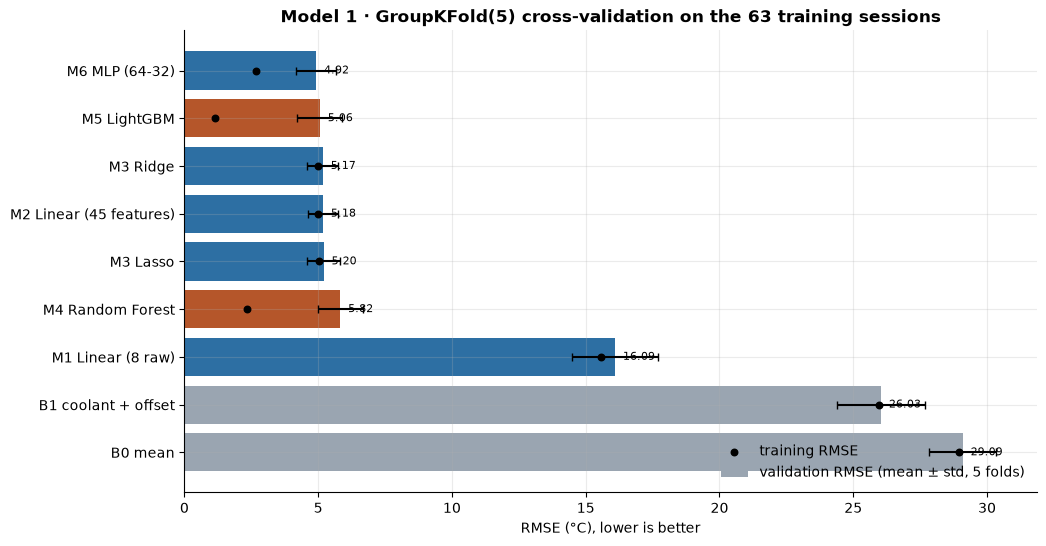

In [12]:
order = cv_results.sort_values("rmse_mean", ascending=False)
fig, ax = plt.subplots(figsize=(11, 6))
ypos = np.arange(len(order))
bar_colors = [COLORS["stator_winding"] if n.startswith(("M4", "M5")) else ("#9aa5b1" if n.startswith("B") else COLORS["coolant"]) for n in order["model"]]
ax.barh(ypos, order["rmse_mean"], xerr=order["rmse_std"], color=bar_colors, capsize=3, label="validation RMSE (mean ± std, 5 folds)")
ax.scatter(order["train_rmse_mean"], ypos, color="black", zorder=3, s=22, label="training RMSE")
for yp, v in zip(ypos, order["rmse_mean"]):
    ax.text(v + 0.3, yp, f"{v:.2f}", va="center", fontsize=8)
ax.set_yticks(ypos)
ax.set_yticklabels(order["model"])
ax.set_xlabel("RMSE (°C), lower is better")
ax.set_title("Model 1 · GroupKFold(5) cross-validation on the 63 training sessions")
ax.legend(loc="lower right")
save_figure(fig, "model_01_cv_comparison.png")
plt.show()

**Figure:** how the regularisation strength α changes Ridge and Lasso. With too little penalty the model overfits correlated features; with too much it underfits (it becomes too simple).

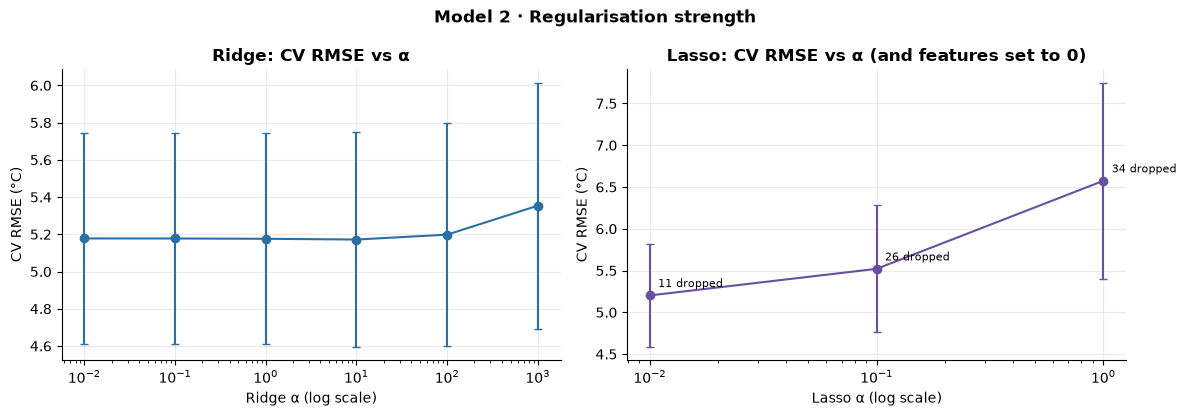

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].errorbar(ridge_tuning["alpha"], ridge_tuning["rmse_mean"], yerr=ridge_tuning["rmse_std"], marker="o", color=COLORS["coolant"], capsize=3)
axes[0].set_xscale("log")
axes[0].set_xlabel("Ridge α (log scale)")
axes[0].set_ylabel("CV RMSE (°C)")
axes[0].set_title("Ridge: CV RMSE vs α")
axes[1].errorbar(lasso_tuning["alpha"], lasso_tuning["rmse_mean"], yerr=lasso_tuning["rmse_std"], marker="o", color=COLORS["speed"], capsize=3)
for a, r, d in zip(lasso_tuning["alpha"], lasso_tuning["rmse_mean"], lasso_tuning["features_dropped"]):
    axes[1].annotate(f"{d} dropped", (a, r), textcoords="offset points", xytext=(6, 6), fontsize=8)
axes[1].set_xscale("log")
axes[1].set_xlabel("Lasso α (log scale)")
axes[1].set_ylabel("CV RMSE (°C)")
axes[1].set_title("Lasso: CV RMSE vs α (and features set to 0)")
fig.suptitle("Model 2 · Regularisation strength", fontweight="bold")
fig.tight_layout()
save_figure(fig, "model_02_regularisation.png")
plt.show()

## 11. Per-fold detail of the best model
The ± std hides the per-fold scores. Looking at them shows whether one group of sessions is much harder than the others.

In [14]:
best_name = cv_results.loc[0, "model"]
fold_tables[best_name][["fold", "rmse", "mae", "r2", "max_abs_error", "train_rmse", "fit_seconds"]].round(3)

,fold,rmse,mae,r2,max_abs_error,train_rmse,fit_seconds
0,0,5.215,2.850,0.961,76.306,2.688,13.463
1,1,5.967,3.982,0.962,45.108,2.514,16.362
2,2,4.449,2.853,0.976,47.670,2.724,17.845
3,3,5.231,3.401,0.970,44.129,2.537,18.594
4,4,3.734,2.492,0.981,63.864,2.853,19.263


## 12. What does thinning to every 10th row cost? (plan 3.6 / N6)
We re-run the best LightGBM configuration with **every 5th row** (twice the data) and compare its CV RMSE and time.

In [15]:
cv5 = train.iloc[::5]
start = time.time()
fold_k5, _ = group_cv(lgb.LGBMRegressor(subsample_freq=1, n_jobs=N_JOBS, random_state=config.SEED, verbose=-1, **best_lgbm_params),
                      cv5[FEATURES], cv5[config.TARGET].astype("float64"), cv5[config.GROUP])
k5_seconds = time.time() - start
k10_rmse = float(cv_results.loc[cv_results["model"] == "M5 LightGBM", "rmse_mean"].iloc[0])
k5_rmse = float(fold_k5["rmse"].mean())
print(f"LightGBM CV RMSE: every 10th row {k10_rmse:.3f} °C | every 5th row {k5_rmse:.3f} °C "
      f"(difference {k5_rmse - k10_rmse:+.3f} °C); fit time per fold {fold_tables['M5 LightGBM']['fit_seconds'].mean():.1f} s vs {fold_k5['fit_seconds'].mean():.1f} s")
K_FINAL_LGBM = 5 if (k10_rmse - k5_rmse) > 0.05 else 10
print("Rows used for the final LightGBM fit: every", K_FINAL_LGBM, "th training row")

LightGBM CV RMSE: every 10th row 5.061 °C | every 5th row 5.146 °C (difference +0.085 °C); fit time per fold 5.8 s vs 12.5 s
Rows used for the final LightGBM fit: every 10 th training row


## 13. Choose the finalists (`[DECISION]`)
**Rule (fixed before looking at the table):**
1. Rank by CV RMSE.
2. The best model is finalist 1.
3. The best model of a *different family* is finalist 2.
4. The best **linear** model is finalist 3, as the simple, cheap option for a motor controller.
5. If a simpler model is within **0.3 °C** of the best, we discuss the trade-off.

In [16]:
family = {"B0 mean": "baseline", "B1 coolant + offset": "baseline", "M1 Linear (8 raw)": "linear", "M2 Linear (45 features)": "linear",
          "M3 Ridge": "linear", "M3 Lasso": "linear", "M4 Random Forest": "forest", "M5 LightGBM": "boosting", "M6 MLP (64-32)": "neural"}
ranked = cv_results[cv_results["model"].map(family) != "baseline"].copy()
ranked["family"] = ranked["model"].map(family)
finalist_1 = ranked.iloc[0]["model"]
finalist_2 = ranked[ranked["family"] != family[finalist_1]].iloc[0]["model"]
best_linear = ranked[ranked["family"] == "linear"].iloc[0]["model"]
finalists = [finalist_1, finalist_2] + ([best_linear] if best_linear not in (finalist_1, finalist_2) else [])
best_rmse = float(ranked.iloc[0]["rmse_mean"])
close = ranked[(ranked["rmse_mean"] - best_rmse) <= 0.3]["model"].tolist()
print("Finalists:", finalists)
print(f"Models within 0.3 °C of the best ({best_rmse:.3f} °C):", close)

Finalists: ['M6 MLP (64-32)', 'M5 LightGBM', 'M3 Ridge']
Models within 0.3 °C of the best (4.919 °C): ['M6 MLP (64-32)', 'M5 LightGBM', 'M3 Ridge', 'M2 Linear (45 features)', 'M3 Lasso']


## 14. Out-of-fold errors of the best model (needed for the Phase 6 safety margin)
The **out-of-fold (OOF)** predictions are the predictions each training row got while its own fold was held out. They tell us how big the model's errors on *unseen sessions* typically are, without touching the test set. Phase 6 uses their standard deviation as a safety margin.

In [17]:
oof_res = oofs[finalist_1] - y.to_numpy()
oof_stats = {"model": finalist_1, "residual_mean": float(oof_res.mean()), "residual_std": float(oof_res.std()),
             "residual_p95_abs": float(np.percentile(np.abs(oof_res), 95)), "residual_min": float(oof_res.min()),
             "residual_max": float(oof_res.max())}
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in oof_stats.items()})

{'model': 'M6 MLP (64-32)', 'residual_mean': -0.466, 'residual_std': 4.959, 'residual_p95_abs': 9.413, 'residual_min': -47.67, 'residual_max': 76.306}


## 15. Retrain the finalists on all training sessions and save them
Now each finalist is fitted once on **all 63 training sessions**:
- **LightGBM** uses the row thinning chosen in section 12.
- **Random Forest** uses every 10th row with 300 trees (more trees only make the average smoother).
- **Ridge** is cheap enough to use every row.

Each model is saved with `joblib`, next to a metadata file that lists its inputs, settings, library versions and the split it came from.

In [18]:
def fit_final(name):
    if name == "M5 LightGBM":
        rows = train.iloc[::K_FINAL_LGBM]
        model = lgb.LGBMRegressor(subsample_freq=1, n_jobs=N_JOBS, random_state=config.SEED, verbose=-1, **best_lgbm_params)
        params, k = best_lgbm_params, K_FINAL_LGBM
    elif name == "M4 Random Forest":
        rows = train.iloc[::10]
        model = RandomForestRegressor(n_estimators=300, max_samples=0.5, n_jobs=N_JOBS, random_state=config.SEED, **best_rf_params)
        params, k = {**best_rf_params, "n_estimators": 300}, 10
    elif name == "M3 Ridge":
        rows = train
        model = Pipeline([("scale", StandardScaler()), ("model", Ridge(alpha=best_ridge_alpha))])
        params, k = {"alpha": best_ridge_alpha}, 1
    elif name == "M3 Lasso":
        rows = train
        model = Pipeline([("scale", StandardScaler()), ("model", Lasso(alpha=best_lasso_alpha, max_iter=5000))])
        params, k = {"alpha": best_lasso_alpha}, 1
    elif name == "M6 MLP (64-32)":
        rows = train.iloc[::10]
        model = mlp
        params, k = {"hidden_layer_sizes": [64, 32], "max_iter": 40}, 10
    else:
        rows = train
        model = Pipeline([("scale", StandardScaler()), ("model", LinearRegression())])
        params, k = {}, 1
    start = time.time()
    model.fit(rows[FEATURES], rows[config.TARGET].astype("float64"))
    seconds = time.time() - start
    file_name = name.split(" ")[0].lower() + "_" + "_".join(name.split(" ")[1:]).lower().replace("(", "").replace(")", "").replace("-", "_") + ".joblib"
    joblib.dump(model, config.MODELS_DIR / file_name)
    size_mb = (config.MODELS_DIR / file_name).stat().st_size / 1e6
    print(f"{name}: fitted on {len(rows)} rows in {seconds:.1f} s -> {file_name} ({size_mb:.1f} MB)")
    return {"model": name, "file": f"outputs/models/{file_name}", "params": params, "row_step": k,
            "fit_rows": int(len(rows)), "fit_seconds": round(seconds, 1), "file_mb": round(size_mb, 2),
            "cv_rmse": float(cv_results.loc[cv_results["model"] == name, "rmse_mean"].iloc[0])}

final_models = [fit_final(name) for name in finalists]

M6 MLP (64-32): fitted on 118980 rows in 77.6 s -> m6_mlp_64_32.joblib (0.1 MB)


M5 LightGBM: fitted on 118980 rows in 22.4 s -> m5_lightgbm.joblib (1.5 MB)


M3 Ridge: fitted on 1189792 rows in 2.9 s -> m3_ridge.joblib (0.0 MB)


In [19]:
metadata = {
    "created": "notebooks/04_modelling.ipynb",
    "features": FEATURES,
    "target": config.TARGET,
    "split_file": "outputs/results/split_profiles.json",
    "train_profiles": split["train_profiles"],
    "finalists": final_models,
    "versions": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__, "lightgbm": lgb.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__},
    "note": "Model files are git-ignored. Re-create them by running this notebook.",
}
for path in [config.MODELS_DIR / "model_metadata.json", config.RESULTS_DIR / "model_metadata.json"]:
    with open(path, "w") as f:
        json.dump(metadata, f, indent=2)
print("Saved model metadata")

Saved model metadata


## 16. Set the numeric success target (`[DECISION]`, decided before the test set is opened)
`docs/problem.md` said we would set the target only after the baselines were known. Now that they are:
- **Target 1 (accuracy):** the final model's **test RMSE ≤ its CV RMSE + 2 × its CV std**, rounded up to 0.1 °C. If test sessions behave like training sessions, this should hold; if it fails, the model generalises worse than CV promised.
- **Target 2 (value over the baselines):** test RMSE at most **half** of the B1 (coolant + offset) baseline's CV RMSE.

In [20]:
best_row = cv_results[cv_results["model"] == finalist_1].iloc[0]
target_rmse = float(np.ceil((best_row["rmse_mean"] + 2 * best_row["rmse_std"]) * 10) / 10)
target_vs_b1 = float(b1["rmse_mean"] / 2)
print(f"Target 1: test RMSE of {finalist_1} <= {target_rmse:.1f} °C")
print(f"Target 2: test RMSE <= {target_vs_b1:.2f} °C (half of B1's CV RMSE {b1['rmse_mean']:.2f} °C)")

Target 1: test RMSE of M6 MLP (64-32) <= 6.5 °C
Target 2: test RMSE <= 13.02 °C (half of B1's CV RMSE 26.03 °C)


In [21]:
summary = {
    "cv_rows": int(len(cv_data)), "k_cv": K_CV, "n_sessions": int(groups.nunique()), "n_folds": 5,
    "cv_table": cv_results.drop(columns=["params"]).round(4).to_dict(orient="records"),
    "best_ridge_alpha": best_ridge_alpha, "best_lasso_alpha": best_lasso_alpha, "lasso_dropped": dropped,
    "best_rf_params": best_rf_params, "best_lgbm_params": best_lgbm_params,
    "subsampling_check": {"k10_rmse": round(k10_rmse, 4), "k5_rmse": round(k5_rmse, 4), "k5_total_seconds": round(k5_seconds, 1),
                          "k_final_lgbm": K_FINAL_LGBM},
    "finalists": finalists, "models_within_0p3": close,
    "oof_best": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in oof_stats.items()},
    "success_target": {"test_rmse_max": target_rmse, "test_rmse_max_vs_b1": round(target_vs_b1, 3)},
    "best_fold_table": fold_tables[best_name].round(4).to_dict(orient="records"),
}
with open(config.RESULTS_DIR / "modelling_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print("Saved modelling_summary.json")

Saved modelling_summary.json


## 17. What we found (numbers from the outputs above, `cv_results.csv` and `modelling_summary.json`)
- **Features are the big win:** the same Linear Regression goes from **16.09 °C** (8 raw inputs, M1) to **5.18 °C** (45 features, M2), 68 % less error. Every model with the 45 features lands between 4.9 and 5.9 °C.
- **Ranking (CV RMSE, mean ± std):**

  | Model | CV RMSE (°C) | Training RMSE (°C) |
  |---|---|---|
  | M6 MLP | 4.92 ± 0.76 | 2.66 |
  | M5 LightGBM | 5.06 ± 0.84 | 1.14 |
  | M3 Ridge | 5.17 ± 0.58 | 4.99 |
  | M2 Linear | 5.18 ± 0.57 | 4.99 |
  | M3 Lasso | 5.20 ± 0.62 | 5.05 |
  | M4 Random Forest | 5.82 ± 0.84 | 2.33 |
  | M1 Linear (8 raw) | 16.09 ± 1.60 | 15.55 |
  | B1 coolant + offset | 26.03 ± 1.64 | 25.94 |
  | B0 mean | 29.09 ± 1.26 | 28.96 |

- **Baselines:** reading the coolant (B1, 26.03 °C) is barely better than guessing the mean (B0, 29.09 °C). The coolant alone doesn't explain the winding.
- **Overfitting is visible:** the tree models fit their training rows far better than new sessions (LightGBM 1.14 vs 5.06 °C, Random Forest 2.33 vs 5.82 °C). The linear models have almost no gap (4.99 vs 5.17 °C).
- **Finalists (rule fixed in section 13):** **M6 MLP** (best), **M5 LightGBM** (best other family), **M3 Ridge** (best linear). Five models are within 0.3 °C of the best, so the trade-off matters: Ridge is only 0.25 °C worse, has the smallest fold spread (± 0.58), is 45 weights (a 3 KB file) and is fully explainable. That makes it a strong choice for a real motor controller.
- **Thinning check:** every 5th row gave 5.146 °C vs 5.061 °C with every 10th (+0.085 °C, within fold noise) at twice the time, so 10× thinning costs nothing measurable.
- **Big single errors:** the MLP's worst error per fold is 44–76 °C, while 95 % of out-of-fold errors are below 9.41 °C. **Hypothesis**, to check in Phase 5: these happen at the start of sessions that begin already hot (16 of 63 training sessions start above 30 °C), where the EWMA memory has no history.
- **Success targets for Phase 5 (set now, before the test):** test RMSE of the MLP **≤ 6.5 °C**, and **≤ 13.02 °C** (half of B1's CV RMSE).
